# The Coach Who Cannot Play
### In a study published in 1983, ordinary people governed a simulated town and failed in patterns a psychologist later catalogued. I put a machine judge that cannot write through trials built from that catalogue, then gave it the trainer's job over an AI mayor.
**Three parts: how people fail in complex situations, whether a machine judge fails the same way, and what happens when it coaches a machine.**

> **A machine judge is only as good as the model of the situation that code hands it.**

One of Dietrich Dörner's simulated mayors decided that the old people of their town needed better access to telephones. They worked out the average walking time to every phone booth, took a ruler to the map, and fixed the spots where new booths should stand, with great care. The town existed only inside a computer, and it had real problems. By the time the booths were placed, no time was left for any of them.

Dörner, a German psychologist who received the Leibniz Prize in 1986, built such towns to watch people think when the problem is bigger than their head. The one that named his 1983 study is Lohhausen, a small German town of more than 2,000 linked variables, where the participants ran the town under a brief as vague as real briefs are: see to the well-being of the inhabitants. What the study found was that people fail in patterns. By the time Harald Schaub, who worked with Dörner, gathered the patterns into a chapter in 2006, they had names. The mayor with the ruler had taken a "horizontal flight" into a corner they could manage. Others fixed whatever complained loudest, drew compound growth as a straight line, or pursued goals that contradicted each other without noticing.

Schaub opens the chapter with Chernobyl and the ferry Herald of Free Enterprise: errors become visible as accidents, at the level of the operator or the captain, and it is easy to forget that the system's design and management put those people into the error-prone situation. The failures of thinking come before the accident. The chapter ends on a practical claim: a simulation trains people only if the play is analysed afterwards, which rarely works alone, so often it takes a trainer who spots errors, weak points and strengths quickly. A trainer, I would add, does not play.

Forty years on, we are building software to sit in that seat. Agents built on language models run processes, make calls and write the reasons for them, and the common way to check them is to ask another language model for a verdict, which comes back as a score or a preference the judge asserts, with a fluent explanation and no calibrated probability behind it. Jev, a model from the company TypeSafe, is a different kind of judge. It cannot write a word. It answers typed questions about a situation with calibrated probabilities, and its makers publish a list of the ways it fails, a list that reads uncannily like Schaub's list of what makes situations hard.

So I put Jev through Dörner's lab, 44 test cases built from Schaub's six features and 34 written reasons planted with his named errors, and then gave it the trainer's job over an AI mayor of a small lake town.

In [1]:
from pathlib import Path
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "doerner_jev.py").is_file():
    ROOT = ROOT / "doerner"
assert (ROOT / "doerner_jev.py").is_file(), "run the notebook from the folder that holds doerner_jev.py"

# The house palette (quantsoc101's sociodynamics-course/code/sd_style.py), with the same colours inline elsewhere.
sys.path.insert(0, str(ROOT.parent / "sociodynamics-course/code"))
try:
    import sd_style as st
    st.apply()
except ImportError:
    class st:
        BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
        SURFACE, INK, INK2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": st.GRID, "figure.facecolor": st.SURFACE, "axes.facecolor": st.SURFACE})

EXPORT_FIGURES = True
FIG_DIR = ROOT / "images" / "doerner"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Replay only. The keys are blanked before the import and removed after it, so a cache miss raises
# instead of calling a model: every answer below is the one recorded on 2026-10-09.
os.environ["TYPESAFE_API_KEY"] = os.environ["DEEPSEEK_API_KEY"] = ""
sys.path.insert(0, str(ROOT))
import doerner_jev as d
del os.environ["TYPESAFE_API_KEY"], os.environ["DEEPSEEK_API_KEY"]
d.check()   # the town's delay, side effect and budget rule, and the pure helpers


def p_right(answer, expect):
    """The probability Jev put on the right answer."""
    if answer["type"] == "noul":
        return answer["noul"] if expect else 1 - answer["noul"]
    return answer["probabilities"][expect]


# Experiment 1: the lab, Schaub's six features, 44 cases.
lab = []
for feature, cases in d.FEATURES.items():
    for level, expect, state, q in cases():
        a = d.jev(state, {"q": q})["q"]
        right, conf, _ = d.read(a, expect)
        lab.append({"feature": feature, "level": level, "expect": expect, "right": right, "conf": conf,
                    "p_right": p_right(a, expect), "p_yes": a.get("noul")})


def p_yes(feature, level, expect):
    return next(r["p_yes"] for r in lab if r["feature"] == feature and r["level"] == level and r["expect"] == expect)


# Experiment 2: the remedies.
growth = {}
for level, expect, state, q in d.dynamics():
    xs = list(state["lake"]["algae_cover_percent"].values())
    growth[level] = (expect, [d.jev(s, {"q": q})["q"]["noul"]
                              for s in (state, d.growth_words(xs, 20, False), d.growth_words(xs, 20, True))])
words_25 = d.growth_words([1.0 * 1.25 ** i for i in range(6)], 20, True)["lake"]


def chain_words_v0(state):
    """The first version, kept to show the bug: one effect per cause, so a side branch overwrote the main chain."""
    effects = dict(r[5:-1].split(", ", 1) for r in state["rules"])
    node, seen = d.CHAIN[0], []
    while node in effects and len(seen) < 50:
        node = effects[node]
        seen.append(node)
    return {"plan": state["plan"], "consequences_in_order": seen}


chain = {}
for level, expect, state, q in d.interconnectedness():
    chain[(level, expect)] = [d.jev(s, {"q": q})["q"]["noul"] for s in (state, chain_words_v0(state), d.chain_words(state))]

goals = {}
for level, expect, state, q in d.polytely():
    listed = state["council_goals"]
    ps = {k: a["noul"] for k, a in d.jev(state, d.per_goal(listed)).items()}
    top = sorted(ps, key=ps.get, reverse=True)[:2]
    goals[(level, expect)] = {"one": d.jev(state, {"q": q})["q"]["noul"], "found": all(ps[k] >= 0.5 for k in top),
                              "top": [(listed[int(k[1:])], ps[k]) for k in top]}

# Experiment 3: the catalogue on 34 planted reasons, four question sets.
def catalogue(questions):
    out = []
    for label, reasons in d.PLANTED.items():
        truth = "none" if label.startswith("none") else label
        for reason in reasons:
            out.append((label, truth, reason, d.jev({**d.SITUATION, "steward_reason": reason}, questions)))
    return out


v1, v2 = catalogue({"error": d.ERRORS}), catalogue({"error": d.ERRORS_V2})
c1 = catalogue({"error": d.ERRORS_V2, "checks": d.CHECKS_V1})
c2 = catalogue({"error": d.ERRORS_V2, "checks": d.CHECKS_V2})
picked = lambda rows: [(label, truth, a["error"]["choice"], a["error"]["confidence"]) for label, truth, _, a in rows]
decided = lambda rows: [(label, truth, d.decide(a["error"]["choice"], a["checks"]["noul"]), a["checks"]["noul"]) for label, truth, _, a in rows]


# Experiment 4: the coach. The same loop as doerner_jev.run_coach, replayed.
def coach_run(coached, months=12):
    s, history, note, rows = dict(d.START), [], None, []
    for _ in range(months):
        action, reason = d.mayor(s, history, note if coached else None)
        after = d.step(s, action)
        a = d.jev({"town": d.words(s), "steward_reason": reason}, {"error": d.ERRORS_V2, "checks": d.CHECKS_V2, "side": d.SIDE})
        note = d.coach_note(a)
        rows.append({"month": after["month"], "action": after["action"], "algae_before": s["algae"], "algae": after["algae"],
                     "tourism": after["tourism"], "budget": after["budget"], "reason": reason,
                     "error": a["error"]["choice"], "conf": a["error"]["confidence"], "side": a["side"]["noul"],
                     "flags": d.behaviour(s, after, [h.split(":")[0] for h in history]), "note": note})
        history.append(f"{after['action']}: {reason[:80]}")
        s = after
    return rows, s


runs = {coached: coach_run(coached) for coached in (False, True)}

# Month 3 resampled five times each way (replicate_month3.py, cache bypassed for the mayor): parsed from the transcript.
text = (ROOT / "transcripts" / "replicate_month3.txt").read_text()
samples = {}
for block in re.split(r"# month 3, ", text)[1:]:
    label = block.split(chr(10), 1)[0].strip()
    found = re.findall(r"  \d\. (\w+)\s+jev: (\w+) ([\d.]+), side p=([\d.]+)\n     (.+)", block)
    samples[label] = [{"action": a, "error": e, "conf": float(c), "side": float(p), "reason": r} for a, e, c, p, r in found]

# Every number in the article, once. The asserts pin the prose.
N = {}
N["lab"] = (sum(r["right"] for r in lab), len(lab))
N["conf_right"] = float(np.mean([r["conf"] for r in lab if r["right"]]))
N["conf_wrong"] = float(np.mean([r["conf"] for r in lab if not r["right"]]))
acted = [r for r in lab if r["conf"] >= d.SURE]
N["acted"], N["acted_wrong"], N["deferred"] = len(acted), sum(not r["right"] for r in acted), len(lab) - len(acted)
deferred = [(r["feature"], r["level"], r["expect"]) for r in lab if r["conf"] < d.SURE]
assert N["lab"] == (42, 44) and round(N["conf_right"], 2) == 0.86 and round(N["conf_wrong"], 2) == 0.55, N
assert (N["acted"], N["acted_wrong"], N["deferred"], d.SURE) == (38, 0, 6, 0.7), N
assert sum(f == "dynamics" for f, _, _ in deferred) == 4 and sorted(lv for f, lv, e in deferred if f == "polytely") == ["16 goals", "32 goals"]
assert all(e is False for f, _, e in deferred if f == "polytely"), deferred      # the no-conflict twins

assert [round(p_yes("complexity", "0 distractors", e), 2) for e in (True, False)] == [0.94, 0.12]
assert [round(p_yes("complexity", "1000 distractors", e), 2) for e in (True, False)] == [0.95, 0.09]
assert round(p_yes("complexity", "250 distractors", False), 2) == 0.09 and round(p_yes("complexity", "250 distractors + water decoys", False), 2) == 0.18
assert [round(p_yes("interconnectedness", "11 hops, 16 side rules", e), 2) for e in (True, False)] == [0.72, 0.13]
assert round(p_yes("interconnectedness", "1 hop, 4 side rules", True), 2) == 0.96
unsure = [r for r in lab if r["feature"] == "intransparency" and r["expect"] == "cannot_tell"]
assert all(r["right"] for r in unsure) and len(unsure) == 4 and (round(min(r["conf"] for r in unsure), 2), round(max(r["conf"] for r in unsure), 2)) == (0.8, 0.98)
assert [round(p_yes("novelty", "invented words", e), 2) for e in (True, False)] == [0.79, 0.17]
assert [round(p_yes("novelty", "against world knowledge", e), 2) for e in (True, False)] == [0.78, 0.05]
g = {r["level"]: round(r["p_yes"], 2) for r in lab if r["feature"] == "dynamics"}
assert g["+25% weekly"] == 0.47 and min(g.values()) == 0.31 and max(g.values()) == 0.77, g
assert [round(p_yes("polytely", f"{n} goals", False), 2) for n in (3, 8, 16, 32)] == [0.21, 0.25, 0.43, 0.57]

assert [round(p, 2) for p in growth["+25% weekly"][1]] == [0.47, 0.71, 0.97]
assert {round(ps[2], 2) for expect, ps in growth.values() if expect} == {0.95, 0.96, 0.97}
assert {round(ps[2], 2) for expect, ps in growth.values() if not expect} == {0.02}
assert "25% per week" in words_25["trend"] and "3.1 weeks" in words_25["trend"] and "week 19" in words_25["projection"], words_25
assert [round(p, 2) for p in chain[("11 hops, 16 side rules", True)]] == [0.72, 0.03, 0.94]
assert [round(chain[("11 hops, 16 side rules", False)][i], 2) for i in (0, 2)] == [0.13, 0.06]
assert round(chain[("6 hops, 12 side rules", True)][1], 2) == 0.07
assert [round(chain[("1 hop, 4 side rules", True)][i], 2) for i in (1, 2)] == [0.70, 0.94]    # conclusions only vs the rules
assert round(goals[("32 goals", False)]["one"], 2) == 0.57 and not goals[("32 goals", False)]["found"]
assert all(goals[(f"{n} goals", True)]["found"] and not goals[(f"{n} goals", False)]["found"] for n in (3, 8, 16, 32))
for n in (3, 8, 16, 32):
    assert {name for name, _ in goals[(f"{n} goals", True)]["top"]} == {"keep the old town completely car-free", "add 200 parking spaces in the old town"}
assert [round(p, 2) for _, p in goals[("32 goals", True)]["top"]] == [0.86, 0.85]

hits = lambda rows: sum(choice == truth for _, truth, choice, _ in rows)
planted = [r for r in picked(v1) if not r[0].startswith("none")]
assert len(planted) == 24 and hits(planted) == 24 and sum(c >= 0.93 for *_, c in planted) == 22
misses = lambda rows: sorted(round(c, 2) for label, truth, choice, c in rows if choice != truth)
assert hits(picked(v1)) == 32 and misses(picked(v1)) == [0.88, 0.95]
assert all(label == "none (near miss)" for label, truth, choice, _ in picked(v1) if choice != truth)
assert hits(picked(v2)) == 32 and misses(picked(v2)) == [0.84, 0.87]
assert hits(decided(c1)) == 29 and hits(decided(c2)) == 33
vetoed = [p for label, truth, choice, p in decided(c1) if truth != "none" and choice == "none"]
assert len(vetoed) == 4 and (round(min(vetoed), 2), round(max(vetoed), 2)) == (0.58, 0.7)
assert not any(truth != "none" and choice == "none" for label, truth, choice, _ in decided(c2))       # no planted error vetoed
near = d.PLANTED["none (near miss)"]
v1_conf = {reason: a["error"]["confidence"] for _, _, reason, a in v1}
assert near[5].startswith("The campaign worked last year") and round(v1_conf[near[5]], 2) == 0.88 and round(v1_conf[near[2]], 2) == 0.95
assert near[1].startswith("I expect the algae to fall next month because the new treatment plant comes online in week 8")
assert round(next(a for _, _, reason, a in c2 if reason == near[5])["checks"]["noul"], 2) == 0.8

assert d.START["growth"] == 0.35 and len(d.ACTIONS) == 4
without, with_ = runs[False][0], runs[True][0]
assert len(without) == len(with_) == 12
assert round(without[1]["side"], 2) == 0.21 and without[1]["action"] == "dredge_lake" and with_[1]["note"]
assert "immediately" in without[1]["reason"] and "earlier phosphate cut should keep reducing algae slowly" in with_[2]["reason"]
assert (without[2]["action"], without[2]["error"], round(without[2]["conf"], 2), round(without[2]["side"], 2)) == ("promote_tourism", "wishful_thinking", 0.76, 0.15)
assert (with_[2]["action"], with_[2]["error"], round(with_[2]["conf"], 2), round(with_[2]["side"], 2)) == ("promote_tourism", "none", 0.4, 0.65)
assert any(f.startswith("repair service") for f in without[2]["flags"]) and (round(without[2]["algae_before"], 1), round(without[2]["algae"], 1)) == (2.0, 2.8)
assert abs(without[2]["algae"] / without[2]["algae_before"] - 1.45) < 1e-9   # month 3: 35% base growth + the dredge's 10 points
assert [round(runs[c][1]["algae"], 1) for c in (False, True)] == [2.1, 2.6] and runs[True][1]["tourism"] == runs[False][1]["tourism"] == 100.0

calm = {**d.START, "month": 5, "growth": 0.0, "tourism": 90.0}
assert d.step({**calm, "algae": 15.0}, "wait")["tourism"] == 95.0 and d.step({**calm, "algae": 16.0}, "wait")["tourism"] == 94.0   # harm starts above 15%
scripted = {}
for name, acts in {"wait": ["wait"] * 12, "chase": ["promote_tourism"] * 12, "cut early": ["cut_phosphate", "wait", "cut_phosphate"] + ["wait"] * 9}.items():
    s = dict(d.START)
    for act in acts:
        s = d.step(s, act)
    scripted[name] = s
assert round(scripted["wait"]["algae"], 1) == round(scripted["chase"]["algae"], 1) == 73.3 and (round(scripted["cut early"]["algae"], 1), scripted["cut early"]["tourism"]) == (10.0, 100.0)

off, on = samples["without the note"], samples["with the note"]
assert len(off) == len(on) == 5 and all(s["action"] == "promote_tourism" for s in off + on)
assert (sum(s["side"] >= 0.5 for s in off), sum(s["side"] >= 0.5 for s in on)) == (2, 5)
assert (round(np.mean([s["side"] for s in off]), 2), round(np.mean([s["side"] for s in on]), 2)) == (0.39, 0.87)
assert not any(s["conf"] >= d.SURE and s["error"] != "none" for s in off + on)
assert [(s["error"], s["conf"]) for s in off if s["error"] != "none"] == [("wishful_thinking", 0.56)]
assert [on[i]["side"] for i in (0, 1, 4)] == [0.69, 0.74, 0.94] and all("earlier phosphate cut" in on[i]["reason"] for i in (0, 1, 4))
assert "runoff" in on[3]["reason"]
month2 = d.step(d.step(dict(d.START), without[0]["action"]), without[1]["action"])   # the state the month-3 prompt saw
for s in off + on:   # the parsed values are the cached answers
    a = d.jev({"town": d.words(month2), "steward_reason": s["reason"]}, {"error": d.ERRORS_V2, "checks": d.CHECKS_V2, "side": d.SIDE})
    assert round(a["side"]["noul"], 2) == s["side"], s

# The figure alt texts quote these too.
dyn_right = sorted(round(r["p_right"], 2) for r in lab if r["feature"] == "dynamics")
assert dyn_right[0] == 0.47 and (dyn_right[1], dyn_right[-1]) == (0.56, 0.77), dyn_right
assert [round(1 - p_yes("polytely", f"{n} goals", False), 2) for n in (3, 8, 16, 32)] == [0.79, 0.75, 0.57, 0.43]
assert round(min(r["p_right"] for r in lab if r["feature"] in ("complexity", "interconnectedness", "intransparency", "novelty")), 2) == 0.72
assert sorted(round(r["conf"], 2) for r in lab if not r["right"]) == [0.53, 0.57]
second = [goals[(f"{n} goals", False)]["top"][1][1] for n in (3, 8, 16, 32)]
weaker = [min(p for _, p in goals[(f"{n} goals", True)]["top"]) for n in (3, 8, 16, 32)]
one_true = [goals[(f"{n} goals", True)]["one"] for n in (3, 8, 16, 32)]
assert (round(min(second), 2), round(max(second), 2)) == (0.15, 0.23) and (round(min(weaker), 2), round(max(weaker), 2)) == (0.79, 0.86)
assert (round(min(one_true), 2), round(max(one_true), 2)) == (0.8, 0.9)
assert (min(s["side"] for s in on), max(s["side"] for s in on)) == (0.69, 0.99)

# The two full runs: the same actions for four months, apart from month 5, and no note in the prompts in between.
assert [r["action"] for r in without[:4]] == [r["action"] for r in with_[:4]] and without[4]["action"] != with_[4]["action"]
assert with_[1]["note"] and with_[2]["note"] is None and with_[3]["note"] is None
assert [without[3][k] for k in ("algae", "tourism", "budget")] == [with_[3][k] for k in ("algae", "tourism", "budget")]

print(f"Ready: lab {N['lab'][0]}/{N['lab'][1]}, catalogue {hits(picked(v1))}/34 then {hits(decided(c2))}/34, "
      f"coach replayed for {len(without)} months twice, {len(off) + len(on)} month-3 samples checked against the cache.")


def finish(fig, name):
    if EXPORT_FIGURES:
        fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

check ok
Ready: lab 42/44, catalogue 32/34 then 33/34, coach replayed for 12 months twice, 10 month-3 samples checked against the cache.


## 1. What the mayors got wrong is not about mayors.

Schaub names six things that make a situation complex, each with its characteristic failure. Too many variables matter, so the solver must set priorities, and sets none or clings to one. The variables are interconnected, a spring mattress, press it here and it moves there, so actions have side effects that go unseen. The system moves while you deliberate, and growth that compounds gets drawn as a straight line. What matters cannot be seen directly, so the solver relies on indicators and picks the wrong ones. Many goals compete, and contradict each other without anyone noticing. And the situation is new, so old knowledge is applied unchecked.

The catalogue of errors that follows is the best part of the chapter, because it is funny in the way true things are. "One suffers from the grievances one has, not from those one does not have," Dörner wrote: the repair-service mayor who patches whatever complains loudest. The Rumpelstiltskin effect is the plan that assumes the best case, today I brew, tomorrow I bake, the day after I fetch the queen's child. There are about forty-five of these, and anyone who has sat through a planning meeting has met most of them.

The remedies are tasks: elaborate the goals and break them into parts, build a model of the system, forecast, check the effects. Errors arise, Schaub writes, when these tasks are not done. Hold on to that list; it comes back in section 5.

## 2. A judge that cannot write.

Jev takes a situation as text and a set of typed questions. A yes-or-no question comes back as a probability, a pick-one question as a choice with a probability on each option, a rubric question as a position on the scale. It does not write replies, produce code or explain its reasoning.

Hand it a town record with the line "reservoir: below the minimum for drinking water since Monday", ask whether the drinking water is at risk, and it answers 0.94; with the reservoir normal, 0.12. The vendor's claim is that such numbers are calibrated across many answers, though no single answer is guaranteed; calibrated means that of the things a model puts at 0.9, roughly nine in ten turn out to be so. A number can be thresholded, logged, compared and, when low, handed to a person. Prose cannot.

The vendor also publishes a page titled "Jev 1.13 jaggedness", a list of the ways this version fails. Jev is not a calculator. It does not count reliably. It reads dates as text. Double negatives and complex indirection cost accuracy, and accuracy falls as the state fills with detail unrelated to the decision. Its advice is to keep the arithmetic in code and send the judge only what the question needs.

Read that list next to Schaub's six features and the experiment suggests itself. Does the judge fail like Dörner's mayors? And if so, do Schaub's remedies work for it?

## 3. Six trials, in Dörner's lab.

For each feature I wrote one fixed question and a family of situations with a known right answer, harder at every level. Most came as twins, one where the answer is yes and one where it is no, so a judge that always says yes scores half.

Complexity: the reservoir, hidden among up to 1,000 loud but irrelevant town facts. Interconnectedness: a plan to close an old weir, and a shuffled rulebook in which the weir raises the river, the river floods a meadow, the meadow closes a road, and so on for up to eleven steps until the school bus cannot run. Dynamics: six weeks of algae readings, and whether algae will cover half the lake by week twenty. Intransparency: does a paper mill pollute a river, when the evidence is a lab test, or only a proxy, a cue, the mill's own statement or a rumour? Many goals: a council's list of 3 to 32 goals, with or without a hidden contradiction. Novelty: a flood chain in familiar words, in invented words, "blorr raises the Quenn", and in rules that contradict what everyone knows.

Figure 1 shows how much probability Jev put on the right answer in each case. Four of the six features did not touch it. The reservoir was found among a thousand facts as surely as among none. The school bus was found eleven steps away, though the margin shrank. When the evidence against the mill was only a proxy, a cue, a self-report or a rumour, it said "cannot tell" every time. Invented words and rules against world knowledge were read as written. On 42 of the 44 cases it was right.

The two that broke it are the two Schaub would have predicted, with a twist. Given six weeks of raw numbers, Jev could barely tell a lake that would be half covered by week twenty from one that would not; its answers sat near a coin flip, and a series growing 25% a week was judged wrong, at 0.47. That is the failure the chapter reports for people. The goal lists broke it the other way round. Dörner's mayors did not notice contradictions between their goals; Jev, asked whether two goals contradict each other when none did, put the probability at 0.21 with three goals and 0.57 with thirty-two. People miss conflicts; the judge drifted toward inventing them.

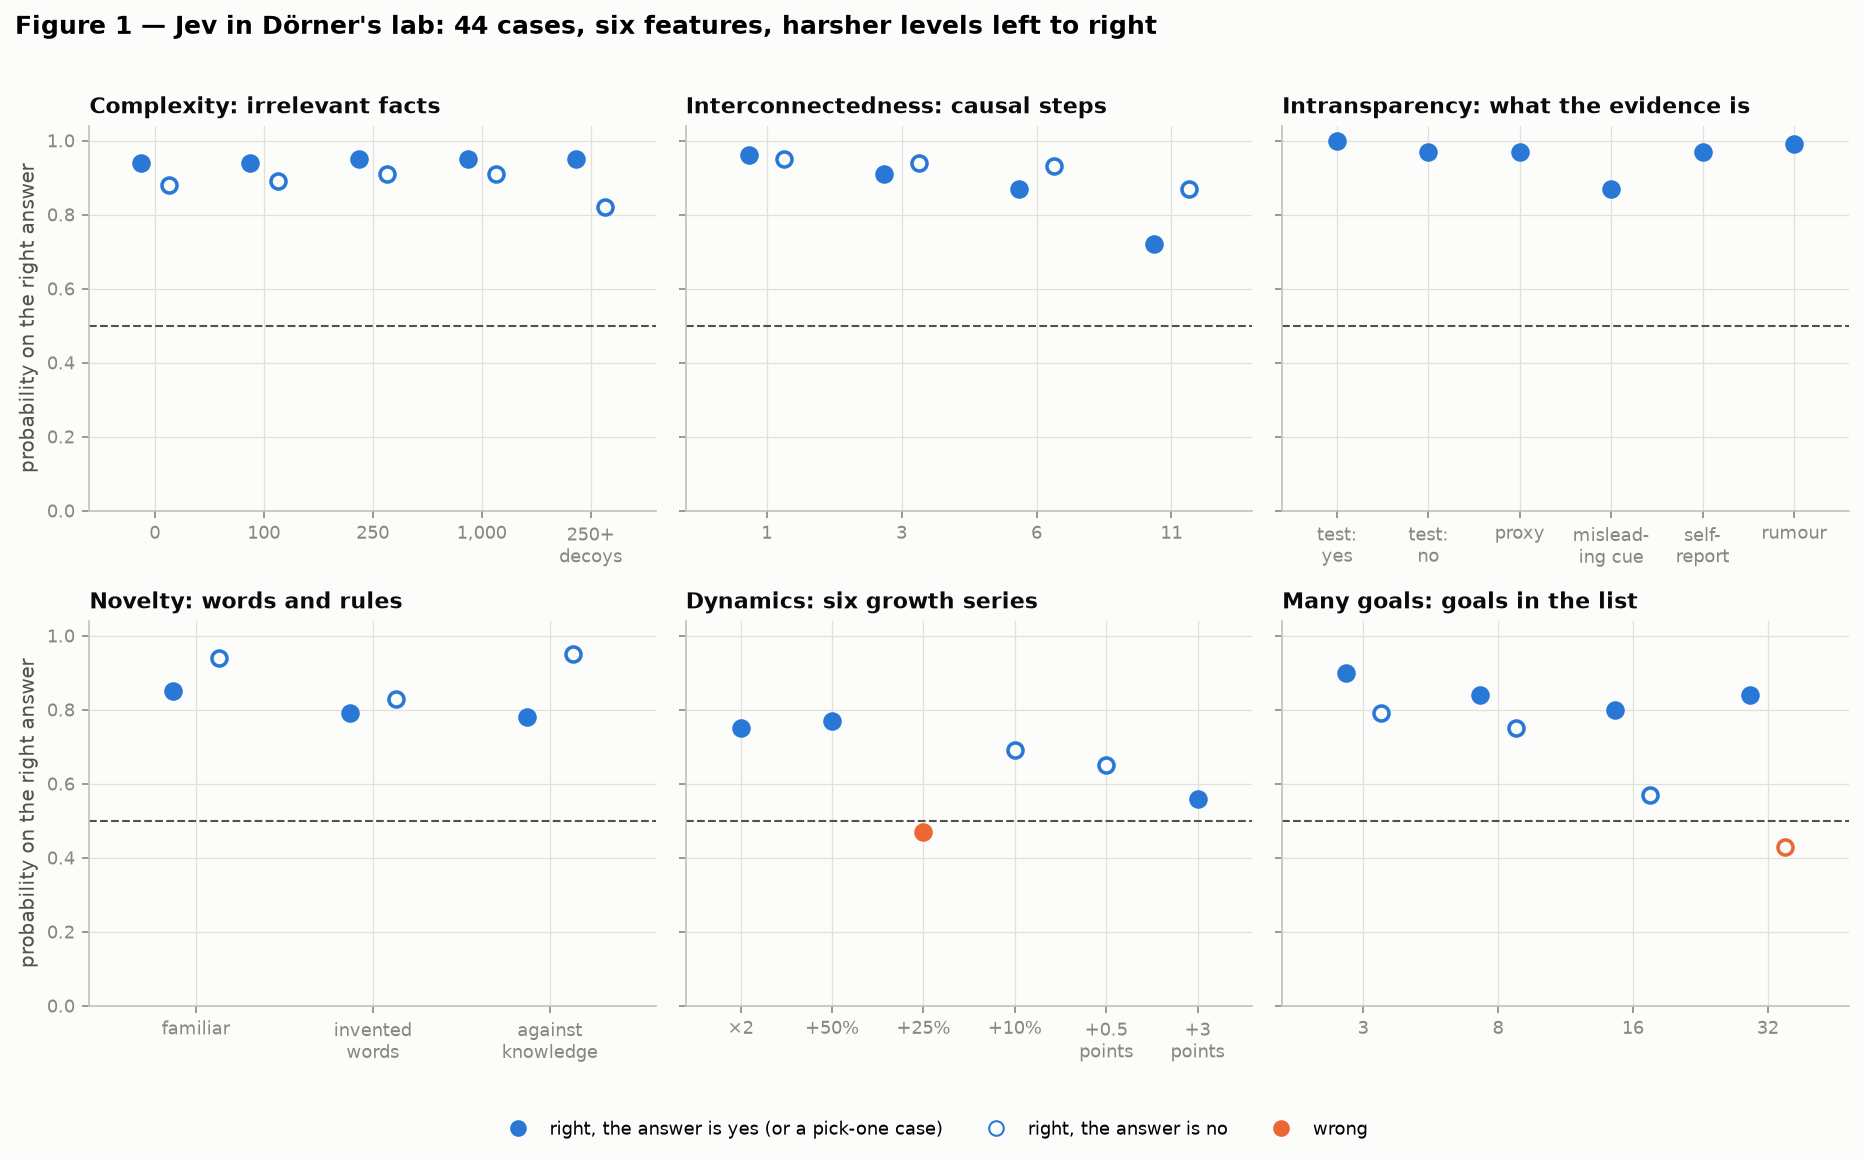

In [2]:
TITLES = {"complexity": "Complexity: irrelevant facts", "interconnectedness": "Interconnectedness: causal steps",
          "intransparency": "Intransparency: what the evidence is", "novelty": "Novelty: words and rules",
          "dynamics": "Dynamics: six growth series", "polytely": "Many goals: goals in the list"}
SHORT = {"0 distractors": "0", "100 distractors": "100", "250 distractors": "250", "1000 distractors": "1,000",
         "250 distractors + water decoys": "250+\ndecoys", "1 hop, 4 side rules": "1", "3 hops, 8 side rules": "3",
         "6 hops, 12 side rules": "6", "11 hops, 16 side rules": "11", "direct test, polluted": "test:\nyes",
         "direct test, clean": "test:\nno", "proxy only": "proxy", "misleading cue": "mislead-\ning cue",
         "self-report only": "self-\nreport", "rumour only": "rumour", "familiar": "familiar",
         "invented words": "invented\nwords", "against world knowledge": "against\nknowledge",
         "doubling weekly": "×2", "+50% weekly": "+50%", "+25% weekly": "+25%", "+10% weekly": "+10%",
         "+0.5 points weekly": "+0.5\npoints", "+3 points weekly": "+3\npoints",
         "3 goals": "3", "8 goals": "8", "16 goals": "16", "32 goals": "32"}

fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.6), sharey=True)
for ax, (feature, title) in zip(axes.flat, TITLES.items()):
    rows = [r for r in lab if r["feature"] == feature]
    levels = list(dict.fromkeys(r["level"] for r in rows))
    paired = {lv for lv in levels if sum(r["level"] == lv for r in rows) == 2}
    for r in rows:
        x = levels.index(r["level"]) + ((-0.13 if r["expect"] is True else 0.13) if r["level"] in paired else 0)
        color = st.BLUE if r["right"] else st.ORANGE
        face = st.SURFACE if r["expect"] is False else color
        ax.scatter(x, r["p_right"], s=52, color=face, edgecolors=color, linewidths=1.7, zorder=3)
    ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
    ax.set_xticks(range(len(levels)), [SHORT[lv] for lv in levels])
    ax.set_xlim(-0.6, len(levels) - 0.4)
    ax.set_title(title, loc="left", fontsize=10.5)
    ax.set_ylim(0, 1.04)
for ax in axes[:, 0]:
    ax.set_ylabel("probability on the right answer")
handles = [plt.Line2D([], [], marker="o", ls="", color=st.BLUE, markersize=7, label="right, the answer is yes (or a pick-one case)"),
           plt.Line2D([], [], marker="o", ls="", markerfacecolor=st.SURFACE, markeredgecolor=st.BLUE, markersize=7, label="right, the answer is no"),
           plt.Line2D([], [], marker="o", ls="", color=st.ORANGE, markersize=7, label="wrong")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Figure 1 — Jev in Dörner's lab: 44 cases, six features, harsher levels left to right", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
finish(fig, "01-lab.png")

## 4. It knew when it did not know.

Here the judge parted company with Dörner's mayors. They went wrong with conviction; Schaub traces this to the need to protect one's sense of competence, which makes failure painful to look at. Jev's confidence, averaged over the 44 cases, was 0.86 when it was right and 0.55 when it was wrong (figure 2). Draw a line at 0.7 and let code act only above it, and code acts on 38 cases without a single error and hands six to a person: four of the six growth series and the two longest goal lists without a conflict, exactly where it had failed.

This is C. K. Chow's rule of 1970 for a classifier that may abstain: answer when the top probability clears one minus the cost of abstaining, in units of the cost of an error; otherwise refuse. Read backwards, a floor at 0.7 says that handing a case to a person costs about 30% of a wrong answer. I had set the floor by hand; the rule named what I had assumed. It also carries a warning: it is optimal only when the probabilities are honest, as Hendrickx and colleagues' 2021 survey of reject options notes, and Fumera, Roli and Giacinto proposed in 2000 one threshold per class instead of one for all. In section 6 the probabilities stop being honest.

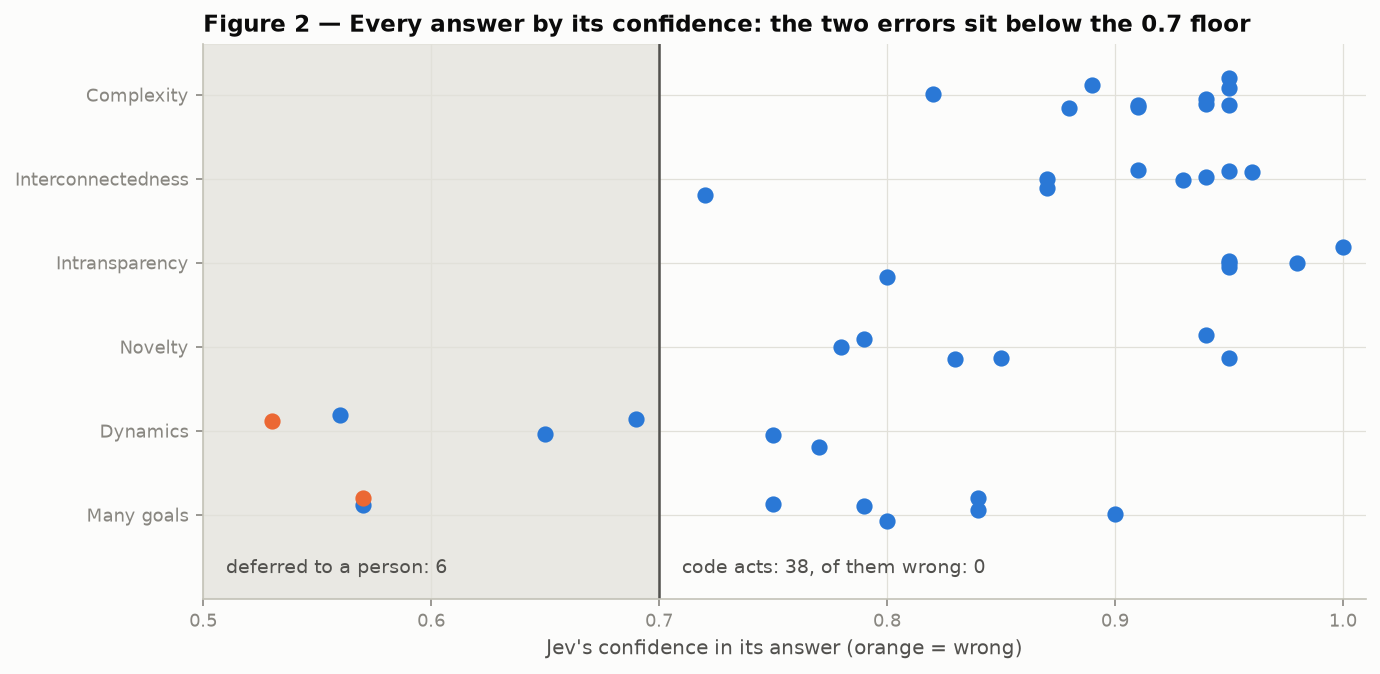

In [3]:
order = list(TITLES)
rng = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(0.5, d.SURE, color=st.GRID, alpha=0.7, zorder=0)
ax.axvline(d.SURE, color=st.INK2, lw=1.2)
for r in lab:
    ax.scatter(r["conf"], order.index(r["feature"]) + rng.uniform(-0.2, 0.2), s=46,
               color=st.BLUE if r["right"] else st.ORANGE, zorder=3)
ax.set_yticks(range(len(order)), [TITLES[f].split(":")[0] for f in order])
ax.invert_yaxis()
ax.set_xlim(0.5, 1.01)
ax.set_xlabel("Jev's confidence in its answer (orange = wrong)")
ax.text(0.51, 5.75, f"deferred to a person: {N['deferred']}", fontsize=9, color=st.INK2, va="bottom")
ax.text(d.SURE + 0.01, 5.75, f"code acts: {N['acted']}, of them wrong: {N['acted_wrong']}", fontsize=9, color=st.INK2, va="bottom")
ax.set_ylim(6.0, -0.6)
ax.set_title("Figure 2 — Every answer by its confidence: the two errors sit below the 0.7 floor", loc="left")
finish(fig, "02-confidence.png")

## 5. Schaub's cure for people is the vendor's cure for the model.

Schaub's remedies, forecast, build a model of the system, break the goals into parts, and the vendor's advice, keep the arithmetic in code, split the interpretation into literal questions, send only what the question needs, are the same list, written for a person and for a model. So each remedy became a few lines of code that run before Jev reads anything, and the failing cases were asked again.

Forecasting first (figure 3). Given the raw numbers, the judge had stayed near a coin flip. Given the rate in words, "cover grows by about 25% per week, so it doubles about every 3.1 weeks", it did better, 0.71 on the series that had failed, but it was still carrying a doubling forward in its head, which is arithmetic. Given the rate plus a projection computed by code, "carried forward at this rate, cover passes 50% in week 19", it answered between 0.95 and 0.97 on the series that pass and 0.02 on the ones that do not. The judge does not need to be taught growth. It needs the growth done.

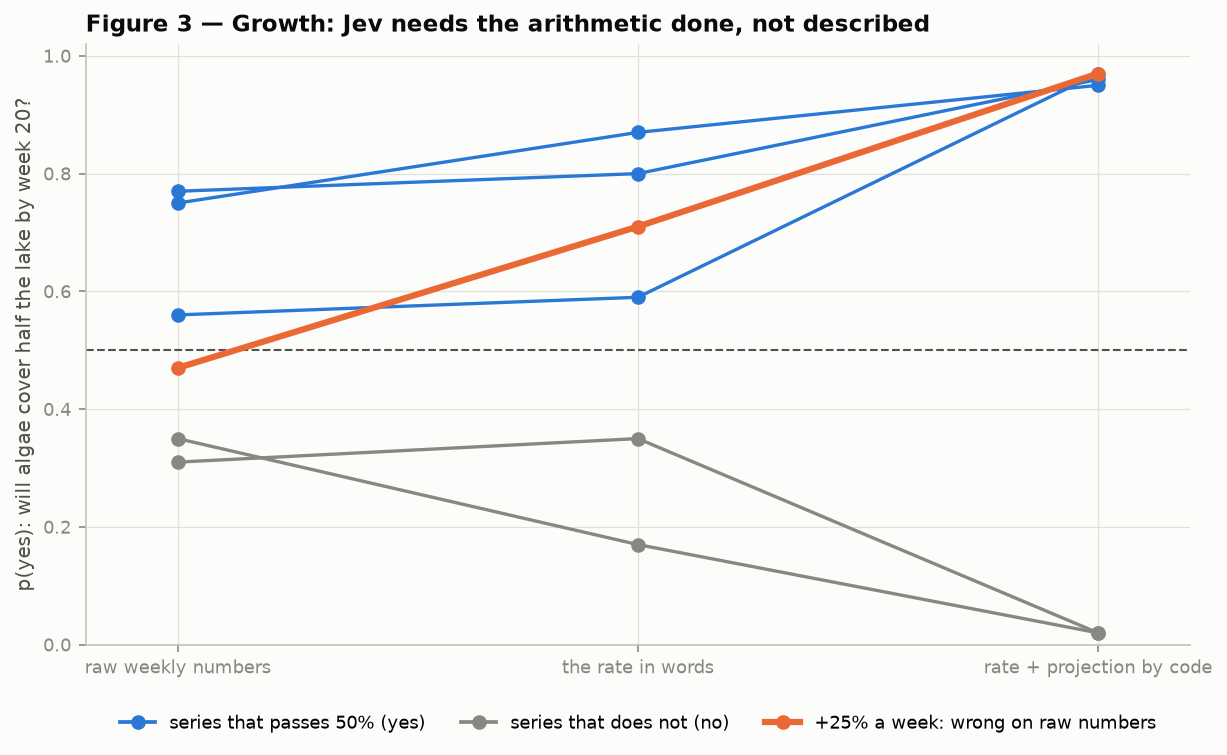

In [4]:
cols = ["raw weekly numbers", "the rate in words", "rate + projection by code"]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for level, (expect, ps) in growth.items():
    focus = level == "+25% weekly"
    ax.plot(range(3), ps, marker="o", lw=3 if focus else 1.6, zorder=3 if focus else 2,
            color=st.ORANGE if focus else (st.BLUE if expect else st.MUTED))
ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
ax.set_xticks(range(3), cols)
ax.set_xlim(-0.2, 2.2)
ax.set_ylim(0, 1.02)
ax.set_ylabel("p(yes): will algae cover half the lake by week 20?")
ax.legend(handles=[plt.Line2D([], [], color=st.BLUE, marker="o", label="series that passes 50% (yes)"),
                   plt.Line2D([], [], color=st.MUTED, marker="o", label="series that does not (no)"),
                   plt.Line2D([], [], color=st.ORANGE, marker="o", lw=3, label="+25% a week: wrong on raw numbers")],
          loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3)
ax.set_title("Figure 3 — Growth: Jev needs the arithmetic done, not described", loc="left")
finish(fig, "03-growth.png")

Model building next. Code walked the declared rules forward from the plan and handed Jev only the ones the plan could reach, in causal order; at eleven steps the true twin moved from 0.72 to 0.94. The judge needs the steps, not the conclusions: only the end of the chain, "the school bus cannot run", scored 0.70 even at one step, while the rule it came from scored 0.94. And my first version of that code kept one effect per cause, so a side branch quietly overwrote the main chain, and Jev answered 0.07 and 0.03 on two cases whose right answer was yes. That is central reduction from Schaub's catalogue, a networked system treated as a single line of causes, committed by my code and caught only because the lab knew the answers. The person who writes that code is subject to the catalogue too.

Goals last (figure 4). One question over thirty-two goals had raised a false alarm. One question per goal, with code deciding that a contradiction needs two goals both flagged, raised none at any length, and where the conflict was real it named the pair: "keep the old town completely car-free" at 0.86, "add 200 parking spaces in the old town" at 0.85.

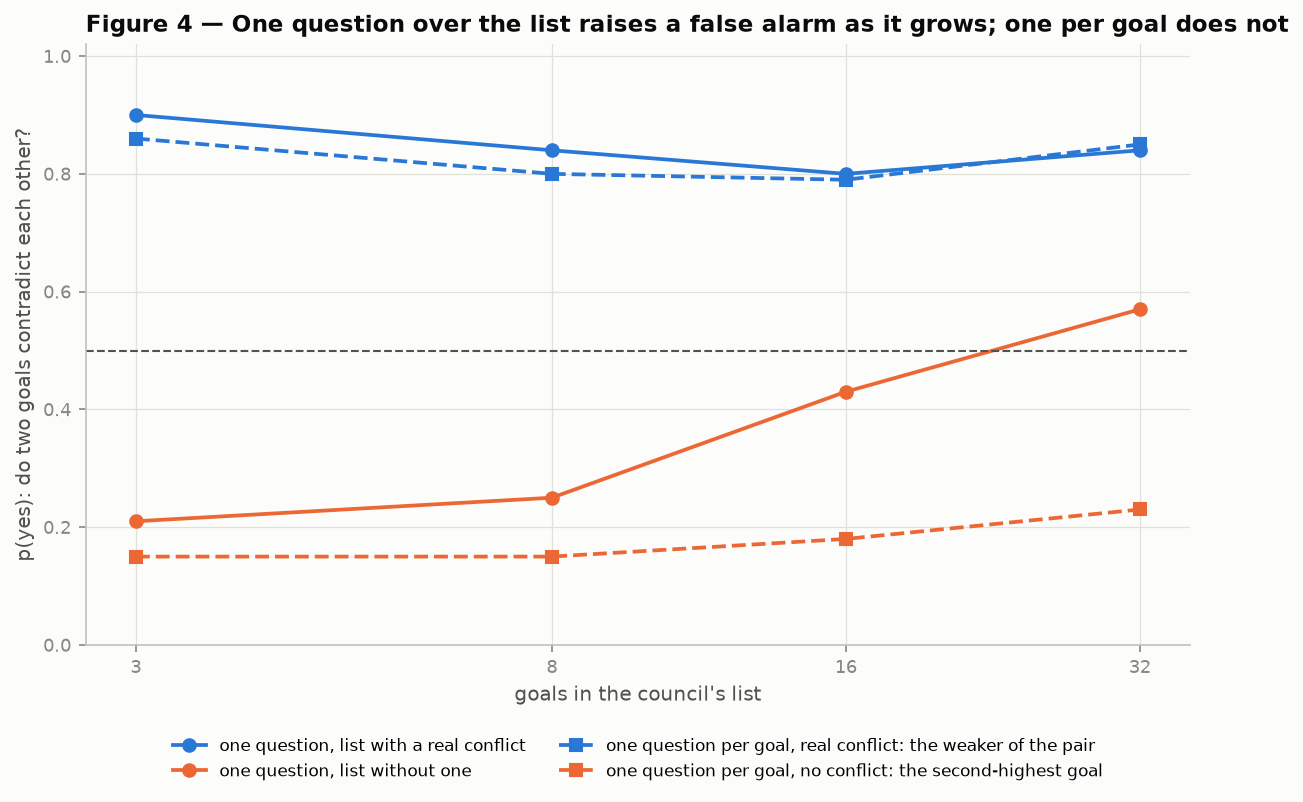

In [5]:
ns = [3, 8, 16, 32]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(ns, [goals[(f"{n} goals", True)]["one"] for n in ns], color=st.BLUE, marker="o", label="one question, list with a real conflict")
ax.plot(ns, [goals[(f"{n} goals", False)]["one"] for n in ns], color=st.ORANGE, marker="o", label="one question, list without one")
ax.plot(ns, [min(p for _, p in goals[(f"{n} goals", True)]["top"]) for n in ns], color=st.BLUE, ls="--", marker="s",
        label="one question per goal, real conflict: the weaker of the pair")
ax.plot(ns, [goals[(f"{n} goals", False)]["top"][1][1] for n in ns], color=st.ORANGE, ls="--", marker="s",
        label="one question per goal, no conflict: the second-highest goal")
ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
ax.set_xscale("log", base=2)
ax.set_xticks(ns, [str(n) for n in ns])
ax.set_ylim(0, 1.02)
ax.set_xlabel("goals in the council's list")
ax.set_ylabel("p(yes): do two goals contradict each other?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8)
ax.set_title("Figure 4 — One question over the list raises a false alarm as it grows; one per goal does not", loc="left")
finish(fig, "04-goals.png")

## 6. Reading the mayor's reasons.

A trainer must recognise the catalogue's errors when a mayor commits one in a sentence. Six of Schaub's errors became one pick-one question with a one-sentence definition each: central reduction, wishful thinking, momentary extrapolation, immunisation, magical hypotheses, methodism (repeating what worked before without checking that the conditions still hold), or none. To know the right answers I planted the reasons: four written to show each error, four clean ones, and six near misses that wear the surface of an error and are not one. A language model wrote them to order, which is a limit.

The plain errors were easy: Jev caught all twenty-four, most at 0.93 or higher. The near misses were where it went wrong, and here, unlike in the lab, it went wrong with conviction (figure 5). "The campaign worked last year because visitors came for the beach; the beach is still clean, so it should fit again. I'll check bookings in two weeks." Methodism, said Jev, at 0.88, although the reason checks exactly the conditions whose absence defines methodism. A reason that extends a compounding trend, with a condition attached, was read as momentary extrapolation at 0.95. No floor catches an error at 0.95.

Rewording the definitions did nothing; the same two came back. Both labels are at bottom a third error in the catalogue, ignoring the conditions under which a measure works, so, as the vendor advises, I asked that as a separate yes-or-no question and let code drop the label when the check passed. My first wording was too soft: four true errors were dropped, a net loss. My second asked for a fact about the present that the reason checks before relying on the past; it cleared the beach near miss, touched no planted error, and left one miss in thirty-four. I wrote it after seeing the misses, so it counts once it holds on new reasons.

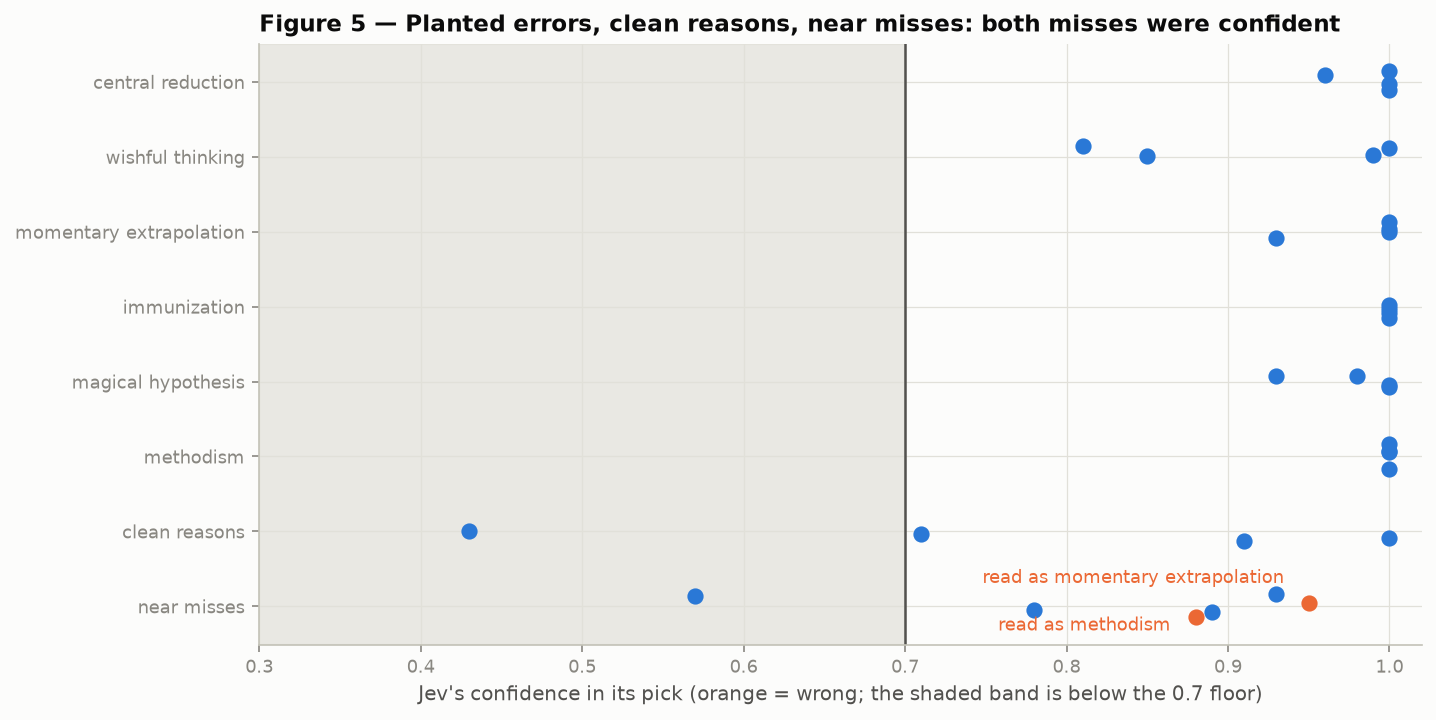

In [6]:
groups = list(d.PLANTED)
names = {"central_reduction": "central reduction", "wishful_thinking": "wishful thinking",
         "momentary_extrapolation": "momentary extrapolation", "immunization": "immunization",
         "magical_hypothesis": "magical hypothesis", "methodism": "methodism", "none": "clean reasons",
         "none (near miss)": "near misses"}
rng = np.random.default_rng(3)
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axvspan(0.3, d.SURE, color=st.GRID, alpha=0.7, zorder=0)
ax.axvline(d.SURE, color=st.INK2, lw=1.2)
for label, truth, choice, conf in picked(v1):
    y = groups.index(label) + rng.uniform(-0.17, 0.17)
    ok = choice == truth
    ax.scatter(conf, y, s=46, color=st.BLUE if ok else st.ORANGE, zorder=3)
    if not ok:
        ax.annotate(f"read as {names[choice]}", (conf, y), xytext=(-12, 12 if choice == "momentary_extrapolation" else -4),
                    textcoords="offset points", fontsize=8.5, color=st.ORANGE, ha="right", va="center")
ax.set_yticks(range(len(groups)), [names[g] for g in groups])
ax.invert_yaxis()
ax.set_xlim(0.3, 1.02)
ax.set_xlabel("Jev's confidence in its pick (orange = wrong; the shaded band is below the 0.7 floor)")
ax.set_title("Figure 5 — Planted errors, clean reasons, near misses: both misses were confident", loc="left")
finish(fig, "05-catalogue.png")

## 7. The coach and the AI mayor.

Then Jev got the trainer's job. I built Lohhausen small: a lake town declared in a few dozen lines of code. Algae is the quiet critical variable, compounding at 35% a month, harming tourism once it covers more than 15% of the lake, and responding to a cut in farm phosphate only from the third month after the order. Tourism is the loud one: it dips every off-season, recovers by itself, and makes the headline whenever it is low. Dredging halves the algae at once but makes it grow faster for two months. Waiting, or chasing the headlines, ends with algae over 73% of the lake; two early phosphate cuts end at 10%, with tourism normal.

The mayor was DeepSeek's flash model, choosing one action a month with a sentence of reason. Jev read every reason, with the town described in words rather than numbers, and answered three questions: which catalogue error, if any, does the reason show; does it check the conditions; does it mention a delayed effect or a side effect of the chosen action. The coach spoke on a confident error or on a reason blind to delays and side effects, and only ever named the error, never what to do. The year ran twice, with the notes passed on and with the coach silent.

In month 2 the mayor dredged, with a reason that spoke of immediate results and said nothing about delayed or side effects; Jev put that at 0.21, and the coach said so. It was the most useful note of the year: that side effect adds ten points to the 45% by which the algae grow in month 3. In month 3 the mayor promoted tourism in both runs; the coached reason now mentioned the slow phosphate effect. One month is one sample, so I asked month 3 again, fresh each time, five times with the note and five without (figure 6). Without the note, two of five reasons named a delayed or side effect; with it, five of five. The action did not move. Promote tourism, ten times out of ten.

Two cautions. In three of the five coached reasons the only delayed effect named belongs to the earlier phosphate cut, not to the campaign just chosen, and Jev, asked about the chosen action, scored them 0.69 to 0.94 anyway: it matched "a delayed effect" without asking whose. And whether the action should have changed, nothing here can say. My code labelled it repair-service behaviour, the loud variable while the critical one grew, but the growth was from 2.0% to 2.8% of the lake, far below the harm line, and both full years ended with a clean lake, at 2.1% and 2.6%. The label is a definition, not a verdict. The two runs did drift apart from month 5 on, but the coach had been silent since month 2, and one run each way cannot tell its delayed influence from noise.

What this is not is Goodhart's law. The mayor was not gaming the referee; the note only ever talked about words, so changed words are what it should produce. What did not happen is the step a trainer exists for, from seeing the flaw in one's own reasoning to reconsidering the decision. Prompted to reflect, the mayor reflected, better, and did the same thing.

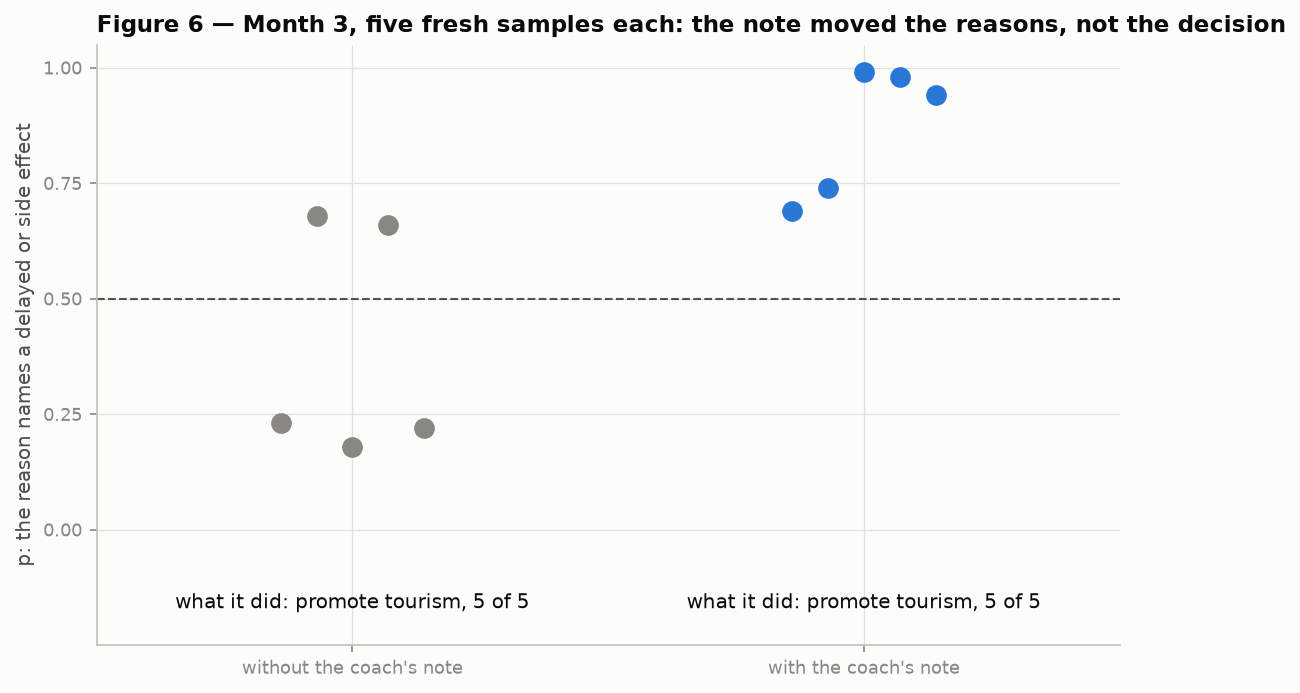

In [7]:
fig, ax = plt.subplots(figsize=(8.8, 5.2))
for i, (label, group) in enumerate((("without the coach's note", off), ("with the coach's note", on))):
    xs = i + np.linspace(-0.14, 0.14, len(group))
    ax.scatter(xs, [s["side"] for s in group], s=80, color=st.BLUE if i else st.MUTED, zorder=3)
    acts = sum(s["action"] == "promote_tourism" for s in group)
    ax.text(i, -0.17, f"what it did: promote tourism, {acts} of {len(group)}", ha="center", fontsize=9.5, color=st.INK)
ax.axhline(0.5, color=st.INK2, lw=1, ls="--")
ax.set_xticks([0, 1], ["without the coach's note", "with the coach's note"])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.25, 1.05)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_ylabel("p: the reason names a delayed or side effect")
ax.set_title("Figure 6 — Month 3, five fresh samples each: the note moved the reasons, not the decision", loc="left")
finish(fig, "06-coach.png")

## 8. What a judge can do, and what it cannot.

The point I would carry into any talk of AI-assisted policy making is this, as an implication, not a finding. A judge model can read a situation that code has prepared, at a size and a distance that would exhaust a person, and say how sure it is. It can read the reasons a policy is given and name the error in them, as long as the error is plain and not a near miss. It cannot tell whether the policy was right. That takes a model of the system, the model building Schaub lists among the tasks his mayors skipped; my code could label a deed at all only because the town was declared with its critical variable named, and in my view real policy seldom writes that model down. Donald Campbell warned in the 1970s that an indicator used for social decisions comes under pressure to be corrupted and distorts what it was meant to monitor; a judge's score on reasons, used at scale, would be such an indicator. That is a prediction this experiment did not test.

If you put a judge model in an agent's loop: keep arithmetic, causal chains and goal lists in code and hand the judge the result; ask one literal question at a time and combine the answers in code; defer to a person below a floor you can defend by its costs, knowing it will not catch confident errors; never let a reading of the reasons stand in for an audit of the actions; and check your own preparation code as hard as the judge.

The numbers are small: 44 lab cases, 34 planted reasons, one year each way and one month sampled five times each way, one town, one judge version, which its vendor expects to improve, one mayor model. The reasons were written to order by a language model, and the second condition question after I had seen the misses. These are demonstrations, not a benchmark. The code, every recorded model answer and the notebook that checks every number here are in the companion repository.

**A machine judge is only as good as the model of the situation that code hands it.** The mayor with the ruler had a model too. It was a model of the wrong thing.

---

*Disclosure: I build LLM systems and drafted this text with one; every number in it is computed in the notebook from the recorded model answers or asserted there against them. Sources: H. Schaub, "Störungen und Fehler beim Denken und Problemlösen", in J. Funke (ed.), Denken und Problemlösen, Hogrefe 2006, pp. 447–482; D. Dörner et al., Lohhausen (1983); D. Dörner, Die Logik des Misslingens (1989); U. Kipman et al., Frontiers in Psychology 13 (2022); the University of Bamberg's Dörner page; TypeSafe, "System One", and "Jev 1.13 jaggedness" (that page reviewed 2026-10-02); L. Zheng et al., "Judging LLM-as-a-Judge", NeurIPS 2023; C. K. Chow, IEEE Transactions on Information Theory 16 (1970), 41–46; G. Fumera, F. Roli and G. Giacinto, Pattern Recognition 33 (2000); K. Hendrickx et al., "Machine Learning with a Reject Option" (2021); D. T. Campbell, Evaluation and Program Planning 2 (1979).*